In [1]:
!python3 --version

Python 3.8.10


In [7]:
import numpy as np
import torch
from model import process_and_segment_image
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import backend as K
from matplotlib import pyplot as plt
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
from deepcell.applications import CytoplasmSegmentation
from deepcell.datasets.cytoplasm import hela_s3
import warnings
from skimage.segmentation import relabel_sequential
from deepcell.applications import CellTracking
from random import sample
import json
import sys
import zipfile
from io import BytesIO
import tifffile
import sys
import pandas as pd
import json
import cv2
import skimage.exposure as skie

sys.path.append('../data-registry/cli/')
from data_utils import DclOutputWriter
from data_utils import load_data_local,dcl_to_binary_mask
from iou_tracking_dcl import find_boundary_box

In [8]:
# The model weights are a .pth file. We have copies on magik and northstar. Reach out to Uriah or Rohit for the path.
model_weight_path = "./.cellsam_assets/mixed_model_inference_balanced.pth"
model = torch.load(model_weight_path, map_location=torch.device("cpu"))

# These are reasonable defaults, but set these as needed for your application
model.bbox_threshold = 0.4/1.05
model.mask_threshold = 0.4/5.05
model.iou_threshold = 0.5/1.05
model = model.eval().cuda()

In [9]:
from tqdm import tqdm
from skimage import measure
# from iou_tracking import IOUTracking
# from data_utils import load_data_local,create_new_lineage_dict,convert_cells,dcl_to_zip
# iou_trackr = IOUTracking()

## Stage 1: CellSAM Segmentation

In [94]:
def load_tiff_as_grayscale(path, channel=None):
    """
    Load a TIFF movie into a (T, Y, X) float32 array.
    Uses tifffile for bit-depth-accurate reading (PIL silently downcasts).

    channel : None | int | 'max' | 'sum'
      None / 0  → channel 0
      int       → specific channel index
      'max'     → channel with highest mean signal
      'sum'     → sum all channels
    """
    # --- tifffile preserves original uint16 bit depth ---
    raw = tifffile.imread(path)
    meta = {
        'path':       path,
        'raw_shape':  raw.shape,
        'raw_dtype':  str(raw.dtype),
        'channel_arg': channel,
    }

    # --- normalise axis order to (T, Y, X) or (T, Y, X, C) ---
    # tifffile may return (T, C, Y, X) for some files
    if raw.ndim == 4:
        # detect channel axis: smallest dim is usually C
        if raw.shape[1] < raw.shape[2] and raw.shape[1] < raw.shape[3]:
            # (T, C, Y, X) → (T, Y, X, C)
            raw = np.moveaxis(raw, 1, -1)
            meta['axis_reorder'] = 'TCYX→TYXC'
        meta['n_channels']    = raw.shape[3]
        meta['channel_means'] = [float(raw[:,:,:,c].mean())
                                  for c in range(raw.shape[3])]
        meta['channel_maxes'] = [int(raw[:,:,:,c].max())
                                  for c in range(raw.shape[3])]
        print(f'Multichannel TIFF: {raw.shape}  dtype={raw.dtype}')
        for c in range(raw.shape[3]):
            print(f'  channel {c}: mean={meta["channel_means"][c]:.1f}  '
                  f'max={meta["channel_maxes"][c]}')

    # --- select / reduce channel ---
    if raw.ndim == 3:
        arr  = raw.astype(np.float32)
        meta['mode'] = 'grayscale_direct'

    elif raw.ndim == 4:
        if channel == 'max':
            selected = int(np.argmax(meta['channel_means']))
        elif channel == 'sum':
            arr  = raw.astype(np.float32).sum(axis=3)
            meta['mode'] = f'sum_{raw.shape[3]}_channels'
            selected = None
        elif channel is None:
            # auto: pick channel with non-zero signal
            nonzero = [c for c in range(raw.shape[3])
                       if meta['channel_means'][c] > 0]
            selected = nonzero[0] if nonzero else 0
            if len(nonzero) > 1:
                # among nonzero channels pick brightest
                selected = nonzero[int(np.argmax(
                    [meta['channel_means'][c] for c in nonzero]))]
            meta['auto_selected'] = selected
        elif isinstance(channel, int):
            if channel >= raw.shape[3]:
                raise ValueError(f'channel={channel} but only '
                                 f'{raw.shape[3]} available')
            selected = channel
        else:
            raise ValueError(f'Unknown channel: {channel!r}')

        if selected is not None:
            arr  = raw[:,:,:,selected].astype(np.float32)
            meta['mode']             = f'channel_{selected}_of_{raw.shape[3]}'
            meta['selected_channel'] = selected

    else:
        raise ValueError(f'Unexpected shape: {raw.shape}')

    assert arr.ndim == 3, f'Expected (T,Y,X), got {arr.shape}'
    meta['output_shape'] = arr.shape
    meta['output_dtype'] = str(arr.dtype)
    meta['output_min']   = float(arr.min())
    meta['output_max']   = float(arr.max())
    meta['output_mean']  = float(arr.mean())

    print(f'\nSelected output: {meta["mode"]}')
    print(f'  shape={arr.shape}  dtype=float32  '
          f'min={meta["output_min"]:.0f}  '
          f'max={meta["output_max"]:.0f}  '
          f'mean={meta["output_mean"]:.1f}')

    return arr, meta

In [83]:
path = './spark_examples/C2-240731_plate2c1xy62.tif'

# ── usage ─────────────────────────────────────────────────────────────────────
arr, meta = load_tiff_as_grayscale(path)          # auto-detect signal channel
# arr, meta = load_tiff_as_grayscale(path, channel=1)   # explicit channel
# arr, meta = load_tiff_as_grayscale(path, channel='max') # brightest channel

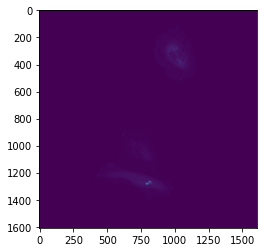

In [92]:
plt.imshow(arr[24,:,:])

In [93]:
# ── segmentation loop with post-processing ───────────────────────────────────
masks_raw = []
for i in tqdm(range(arr.shape[0])):
    X_curr = arr[i, :, :].copy()
    X_curr[X_curr > 3000] = 3000
    X_curr_normalized = X_curr.astype(np.float32)
    img = np.array([X_curr_normalized, X_curr_normalized, X_curr_normalized])
    img = np.moveaxis(img, [0,1,2], [2,0,1])
    try:
        mask, embedding = process_and_segment_image(model, img, normalize=True)
    except:
        print(f"no mask found at frame {i}")
        mask = np.zeros(X_curr.shape)
    masks_raw.append(mask)

100%|██████████████████████████████████████████████████████████████| 61/61 [00:52<00:00,  1.15it/s]


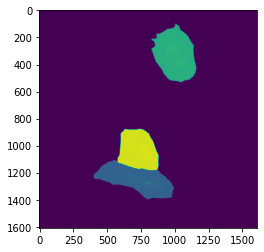

In [95]:
t = 23
plt.imshow(masks_raw[t]*2000 + arr[t,:,:]*0.1)

In [97]:
def compute_iou_matrix(ref_labels, query_labels):
    ref_ids   = np.unique(ref_labels);   ref_ids   = ref_ids[ref_ids != 0]
    query_ids = np.unique(query_labels); query_ids = query_ids[query_ids != 0]

    iou_mat = np.zeros((len(ref_ids), len(query_ids)), dtype=np.float32)
    ior_mat = np.zeros((len(ref_ids), len(query_ids)), dtype=np.float32)
    ioq_mat = np.zeros((len(ref_ids), len(query_ids)), dtype=np.float32)

    for i, rid in enumerate(ref_ids):
        ref_mask = (ref_labels == rid)
        ref_area = ref_mask.sum()
        for j, qid in enumerate(query_ids):
            q_mask       = (query_labels == qid)
            q_area       = q_mask.sum()
            intersection = (ref_mask & q_mask).sum()
            union        = (ref_mask | q_mask).sum()
            iou_mat[i,j] = intersection / union       if union    > 0 else 0
            ior_mat[i,j] = intersection / ref_area    if ref_area > 0 else 0
            ioq_mat[i,j] = intersection / q_area      if q_area   > 0 else 0

    return iou_mat, ior_mat, ioq_mat, ref_ids, query_ids

In [98]:
# ── parameters ───────────────────────────────────────────────────────────────
MIN_CELL_SIZE_PX   = 5000   # px² — discard segments smaller than this
IOU_MERGE_THRESH   = 0.3    # IoU threshold to match oversegmented cells to frame 0

In [99]:
from scipy.ndimage import binary_dilation
# ── helper: filter small segments from a label frame ─────────────────────────
def filter_small_cells(label_frame, min_size=MIN_CELL_SIZE_PX):
    """Remove labelled regions smaller than min_size px². Returns cleaned frame."""
    out = label_frame.copy()
    for r in measure.regionprops(label_frame):
        if r.area < min_size:
            out[label_frame == r.label] = 0
    return out
    
def merge_to_reference(ref_frame, query_frame, origin_frame,
                       iou_thresh=IOU_MERGE_THRESH,
                       ioq_thresh=0.2, dilation_px=20):

    iou_mat, ior_mat, ioq_mat, ref_ids, query_ids = compute_iou_matrix(
        ref_frame, query_frame)
    out     = np.zeros_like(query_frame)
    claimed = set()

    # ── stage 1: greedy match in descending IoR order ────────────────────────
    # build all candidate (ref, query) pairs above any threshold
    candidates = []
    for i, rid in enumerate(ref_ids):
        for j, qid in enumerate(query_ids):
            score = max(ior_mat[i,j], ioq_mat[i,j])
            if score > 0:
                candidates.append((score, i, j, rid, qid))

    # sort descending — assign most confident pairs first
    candidates.sort(key=lambda x: -x[0])

    assigned_refs = set()
    for score, i, j, rid, qid in candidates:
        if rid in assigned_refs or qid in claimed:
            continue
        if ior_mat[i,j] >= iou_thresh or ioq_mat[i,j] >= ioq_thresh:
            out[query_frame == qid] = rid
            claimed.add(qid)
            assigned_refs.add(rid)

    # ── stage 2: soft match for unassigned ref cells ──────────────────────────
    # use a lower threshold but only for unclaimed segments
    for i, rid in enumerate(ref_ids):
        if rid in assigned_refs:
            continue
        avail = [(ior_mat[i,j], ioq_mat[i,j], j, qid)
                 for j, qid in enumerate(query_ids) if qid not in claimed]
        if not avail:
            continue
        best = max(avail, key=lambda x: x[0])
        best_ior, best_ioq, best_j, best_qid = best
        if best_ior >= 0.15 or best_ioq >= 0.3:
            out[query_frame == best_qid] = rid
            claimed.add(best_qid)
            assigned_refs.add(rid)
            print(f'  soft match ref cell {rid} → '
                  f'query {best_qid} (IoR={best_ior:.3f} IoQ={best_ioq:.3f})')
        else:
            print(f'  ref cell {rid} unmatched '
                  f'(best IoR={best_ior:.3f} IoQ={best_ioq:.3f})')

    # ── stage 3: origin recovery for cells absent from ref_frame ─────────────
    origin_ids_arr = np.unique(origin_frame); origin_ids_arr = origin_ids_arr[origin_ids_arr != 0]
    missing_ids    = [oid for oid in origin_ids_arr if oid not in ref_ids]

    if missing_ids:
        _, ior_orig, ioq_orig, _, query_ids_o = compute_iou_matrix(
            origin_frame, query_frame)
        for oid in missing_ids:
            oi    = np.where(origin_ids_arr == oid)[0][0]
            avail = [(ior_orig[oi,j], ioq_orig[oi,j], j, qid)
                     for j, qid in enumerate(query_ids_o) if qid not in claimed]
            if not avail:
                continue
            best_ior, best_ioq, best_j, best_qid = max(avail, key=lambda x: x[0])
            if best_ior >= 0.1 or best_ioq >= 0.3:
                out[query_frame == best_qid] = oid
                claimed.add(best_qid)
                print(f'  recovered cell {oid} → '
                      f'query {best_qid} (IoR={best_ior:.3f} IoQ={best_ioq:.3f})')

    # ── stage 4: dilation for unclaimed segments ──────────────────────────────
    unclaimed_ids = [qid for qid in query_ids if qid not in claimed]
    for qid in unclaimed_ids:
        unclaimed_mask = (query_frame == qid)
        dilated        = binary_dilation(unclaimed_mask, iterations=dilation_px)
        neighbours     = out[dilated & ~unclaimed_mask]
        neighbours     = neighbours[neighbours > 0]
        if neighbours.size > 0:
            absorb_id = np.bincount(neighbours).argmax()
            out[unclaimed_mask] = absorb_id
            print(f'  dilation: segment {qid} ({unclaimed_mask.sum()}px) '
                  f'→ absorbed into cell {absorb_id}')

    return out

In [100]:
# ── updated post-processing loop ─────────────────────────────────────────────
origin_frame = None
masks_clean  = []

for i, mask in enumerate(tqdm(masks_raw)):
    if i == 0:
        ref_frame    = filter_small_cells(mask.astype(np.int32), MIN_CELL_SIZE_PX)
        origin_frame = ref_frame.copy()   # frozen frame 0 reference
        masks_clean.append(ref_frame)
    else:
        frame_merged = merge_to_reference(
            ref_frame, mask.astype(np.int32), origin_frame)
        frame_clean  = filter_small_cells(frame_merged, MIN_CELL_SIZE_PX)
        masks_clean.append(frame_clean)
        ref_frame    = frame_clean

y_old = np.expand_dims(np.array(masks_clean), 3)

  7%|████▏                                                          | 4/61 [00:00<00:06,  9.07it/s]

  dilation: segment 3 (222px) → absorbed into cell 3


 46%|████████████████████████████▍                                 | 28/61 [00:03<00:04,  8.23it/s]

  dilation: segment 3 (322px) → absorbed into cell 2


 52%|████████████████████████████████▌                             | 32/61 [00:03<00:03,  8.10it/s]

...

 90%|███████████████████████████████████████████████████████▉      | 55/61 [00:06<00:00,  8.11it/s]

  dilation: segment 3 (1437px) → absorbed into cell 3


 98%|████████████████████████████████████████████████████████████▉ | 60/61 [00:07<00:00,  6.98it/s]

  dilation: segment 4 (70942px) → absorbed into cell 2
  recovered cell 3 → query 3 (IoR=0.891 IoQ=0.855)


100%|██████████████████████████████████████████████████████████████| 61/61 [00:07<00:00,  8.21it/s]


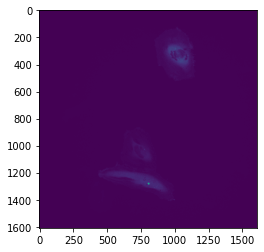

In [101]:
t = 5
plt.imshow(arr[t,:,:])

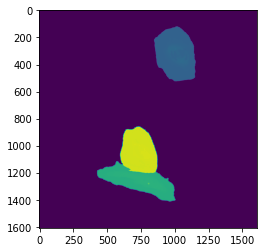

In [102]:
plt.imshow(masks_clean[t]*2000 + arr[t,:,:]*0.1)

In [103]:
# y_old_tracked = iou_trackr.predict(arr,y_old)['y_tracked']

In [104]:
# dcl_ob = {}
# dcl_ob['X'] = np.expand_dims(arr,3)
# dcl_ob['y'] = y_old_tracked.astype('uint8').copy()  # breaks the view
# dcl_ob['cells'] = convert_cells(y_old_tracked)
# dcl_to_zip(filename = "./spark_examples/240731_plate3c1xy60.zip",
#                        X = dcl_ob['X'],
#                        y = dcl_ob['y'],
#                        cells= dcl_ob['cells'],
#                       divisions = [])

---
## SPARK Reporter Signal Quantification

This section implements the SPARK signal quantification method following published protocols:

1. **Puncta segmentation** – Otsu / local-threshold to separate punctate signal from diffuse whole-cell fluorescence.
2. **Whole-cell mask** – derived from the tracked cell segmentation masks produced above (`y_old_tracked`).
3. **SPARK signal** = Σ(puncta pixel intensities) / Σ(whole-cell pixel intensities) per cell per frame.
4. **Normalisation** – optionally normalise each cell's SPARK signal to a reference time-point (e.g. 120 min post-CCCP) or to the mean of a control condition (e.g. DMSO).

> Reference: PINK1-SPARK puncta quantification adapted from Bharat et al. / McWilliams et al. protocols (Analyze Particle / Trainable Weka Segmentation equivalent in Python via `skimage`).

In [105]:
# ── SPARK: additional imports ──────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import filters, morphology, measure, segmentation
from skimage.morphology import remove_small_objects, disk, white_tophat
from scipy import ndimage as ndi
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

In [106]:
# y_old_tracked is (T, Y, X, 1); squeeze the channel dimension
# tracked_masks = y_old_tracked[:, :, :, 0]   # (T, Y, X)
# n_frames = arr.shape[0]


# use post-processed clean masks directly — bypass IOU tracker
tracked_masks = np.array(masks_clean)   # (T, Y, X)
n_frames      = arr.shape[0]

assert tracked_masks.shape == (n_frames, arr.shape[1], arr.shape[2]), \
    f"Shape mismatch: tracked_masks={tracked_masks.shape}  arr={arr.shape}"
print(f'tracked_masks: shape={tracked_masks.shape}  dtype={tracked_masks.dtype}  '
      f'unique_cells={np.unique(tracked_masks).size - 1}')


# # manual reconnecting of tracked result for 62
# for elem in tracked_masks:
#     elem[elem==6]=2
#     elem[elem==4]=3
#     elem[elem==5]=3
#     elem[elem==7]=3
#     elem[elem==8]=3
#     elem[elem==9]=3
#     elem[elem==10]=3
#     elem[elem==11]=3

tracked_masks: shape=(61, 1608, 1608)  dtype=int32  unique_cells=3


In [107]:
# ── SPARK: per-cell adaptive threshold ──────────────────────────────────────
# Instead of a global RAW_THRESH_LOW, compute threshold per cell per frame
# as a high percentile of that cell's intensity distribution.
# This mirrors Fiji's Auto Local Threshold behaviour.

PUNCTA_CELL_PERCENTILE = 99   # percentile of within-cell distribution
                               # tune between 95–99 depending on cell brightness
MIN_PUNCTA_MEAN_INT    = 2600  # mean intensity floor per object
MIN_PUNCTA_SIZE        = 5
MAX_PUNCTA_SIZE        = 1500
NORM_FRAME = None
FRAME_OFFSET_MIN = 0
MINUTES_PER_FRAME = 4

n_frames      = arr.shape[0]
records       = []
CTRL_CELL_IDS = None

In [108]:


for t in tqdm(range(n_frames), desc='Quantifying SPARK signal'):
    frame_img   = tifffile.imread(path, key=t).astype(np.float32)
    label_frame = tracked_masks[t]
    cell_ids    = np.unique(label_frame)
    cell_ids    = cell_ids[cell_ids != 0]

    for cid in cell_ids:
        cell_mask = (label_frame == cid)

        # --- per-cell adaptive threshold ---
        cell_px        = frame_img[cell_mask]
        cell_thresh    = np.percentile(cell_px, PUNCTA_CELL_PERCENTILE)

        # --- whole-cell intensity (all pixels in mask) ---
        cell_total  = float(cell_px.sum())
        cell_area   = int(cell_mask.sum())

        # --- puncta: pixels above per-cell threshold ---
        puncta_mask = (frame_img >= cell_thresh) & cell_mask
        puncta_mask = remove_small_objects(puncta_mask, min_size=MIN_PUNCTA_SIZE)

        # size + mean intensity filter
        puncta_labeled = measure.label(puncta_mask)
        for r in measure.regionprops(puncta_labeled, intensity_image=frame_img):
            if r.area > MAX_PUNCTA_SIZE or r.mean_intensity < MIN_PUNCTA_MEAN_INT:
                puncta_mask[puncta_labeled == r.label] = False
        puncta_labeled = measure.label(puncta_mask)

        puncta_total = float(frame_img[puncta_mask].sum())
        puncta_count = int(puncta_labeled.max())
        puncta_area  = int(puncta_mask.sum())

        spark_signal = puncta_total / cell_total if cell_total > 0 else np.nan

        records.append({
            'frame':            t,
            'time_min':         FRAME_OFFSET_MIN + t * MINUTES_PER_FRAME,
            'cell_id':          int(cid),
            'cell_area_px':     cell_area,
            'cell_total_int':   cell_total,
            'cell_thresh':      float(cell_thresh),   # log for QC
            'puncta_count':     puncta_count,
            'puncta_area_px':   puncta_area,
            'puncta_total_int': puncta_total,
            'spark_signal':     spark_signal,
        })

df_spark = pd.DataFrame(records)
print(df_spark.head(10))
print(f'\nTotal rows: {len(df_spark)}  |  Unique cells: {df_spark.cell_id.nunique()}  |  Frames: {n_frames}')

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:12<00:00,  4.75it/s]

   frame  time_min  cell_id  cell_area_px  cell_total_int  cell_thresh  \
0      0         0        1         93877      66204796.0      2574.00   
1      0         0        2         81958      52033164.0      1699.00   
2      0         0        3         70879      24353328.0       889.00   
3      1         4        1         94333      64931732.0      2121.00   
4      1         4        2         79852      52468492.0      1652.49   
5      1         4        3         70670      25306180.0       861.00   
6      2         8        1         94059      64761604.0      2206.42   
7      2         8        2         77986      51543960.0      1654.15   
8      2         8        3         73873      26010356.0       870.28   
9      3        12        1         93484      64248780.0      2247.00   

   puncta_count  puncta_area_px  puncta_total_int  spark_signal  
0            23             865         2422202.0      0.036587  
1             0               0               0.0    

In [109]:
NORM_FRAME = None

In [110]:
# ── SPARK: normalisation ────────────────────────────────────────────────────
df_norm = df_spark.copy()
# --- Time-course normalisation to a reference frame ---
if NORM_FRAME is not None:
    ref = (df_norm[df_norm['frame'] == NORM_FRAME]
           .set_index('cell_id')['spark_signal']
           .rename('ref_signal'))
    df_norm = df_norm.join(ref, on='cell_id')
    df_norm['spark_norm'] = df_norm['spark_signal'] / df_norm['ref_signal']
    df_norm.drop(columns='ref_signal', inplace=True)
    print(f'Normalised to frame {NORM_FRAME} ({FRAME_OFFSET_MIN + NORM_FRAME * MINUTES_PER_FRAME:.1f} min)')
else:
    df_norm['spark_norm'] = df_norm['spark_signal']   # no normalisation
    print('No time-course normalisation applied (NORM_FRAME=None).')

# --- End-point normalisation to control / DMSO mean ---
if CTRL_CELL_IDS is not None:
    ctrl_mean = df_norm[df_norm['cell_id'].isin(CTRL_CELL_IDS)]['spark_norm'].mean()
    df_norm['spark_norm_ctrl'] = df_norm['spark_norm'] / ctrl_mean
    print(f'Endpoint-normalised to DMSO/control mean SPARK signal = {ctrl_mean:.4f}')
else:
    df_norm['spark_norm_ctrl'] = df_norm['spark_norm']
    print('No control-group normalisation applied (CTRL_CELL_IDS=None).')

df_spark = df_norm
print(df_spark[['frame','time_min','cell_id','spark_signal','spark_norm','spark_norm_ctrl']].head(12))


No time-course normalisation applied (NORM_FRAME=None).
No control-group normalisation applied (CTRL_CELL_IDS=None).
    frame  time_min  cell_id  spark_signal  spark_norm  spark_norm_ctrl
0       0         0        1      0.036587    0.036587         0.036587
1       0         0        2      0.000000    0.000000         0.000000
2       0         0        3      0.000000    0.000000         0.000000
3       1         4        1      0.001547    0.001547         0.001547
4       1         4        2      0.000000    0.000000         0.000000
5       1         4        3      0.000000    0.000000         0.000000
6       2         8        1      0.001338    0.001338         0.001338
7       2         8        2      0.016131    0.016131         0.016131
8       2         8        3      0.000000    0.000000         0.000000
9       3        12        1      0.001451    0.001451         0.001451
10      3        12        2      0.019651    0.019651         0.019651
11      3        12

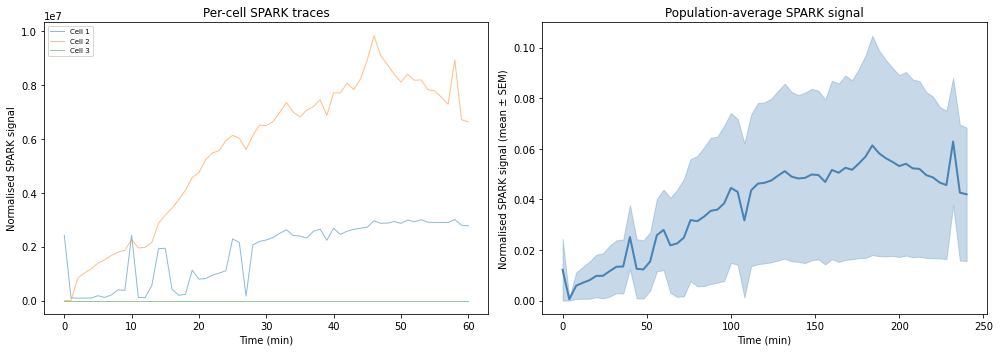

In [111]:
# ── SPARK: visualise signal over time ──────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Per-cell traces
ax = axes[0]
for cid, grp in df_spark.groupby('cell_id'):
    ax.plot(grp['frame'], grp['puncta_total_int'], alpha=0.5, lw=1, label=f'Cell {cid}')
ax.set_xlabel('Time (min)')
ax.set_ylabel('Normalised SPARK signal')
ax.set_title('Per-cell SPARK traces')
if df_spark['cell_id'].nunique() <= 12:
    ax.legend(fontsize=7, loc='upper left')

# Mean ± SEM across all cells
ax2 = axes[1]
summary = (df_spark.groupby('time_min')['spark_norm_ctrl']
           .agg(['mean', 'sem']).reset_index())
ax2.plot(summary['time_min'], summary['mean'], color='steelblue', lw=2)
ax2.fill_between(summary['time_min'],
                  summary['mean'] - summary['sem'],
                  summary['mean'] + summary['sem'],
                  alpha=0.3, color='steelblue')
ax2.set_xlabel('Time (min)')
ax2.set_ylabel('Normalised SPARK signal (mean ± SEM)')
ax2.set_title('Population-average SPARK signal')

plt.tight_layout()
plt.savefig('./spark_examples/spark_signal_timecourse.png', dpi=150)
plt.show()


Saved → spark_paper_figure.pdf / .png


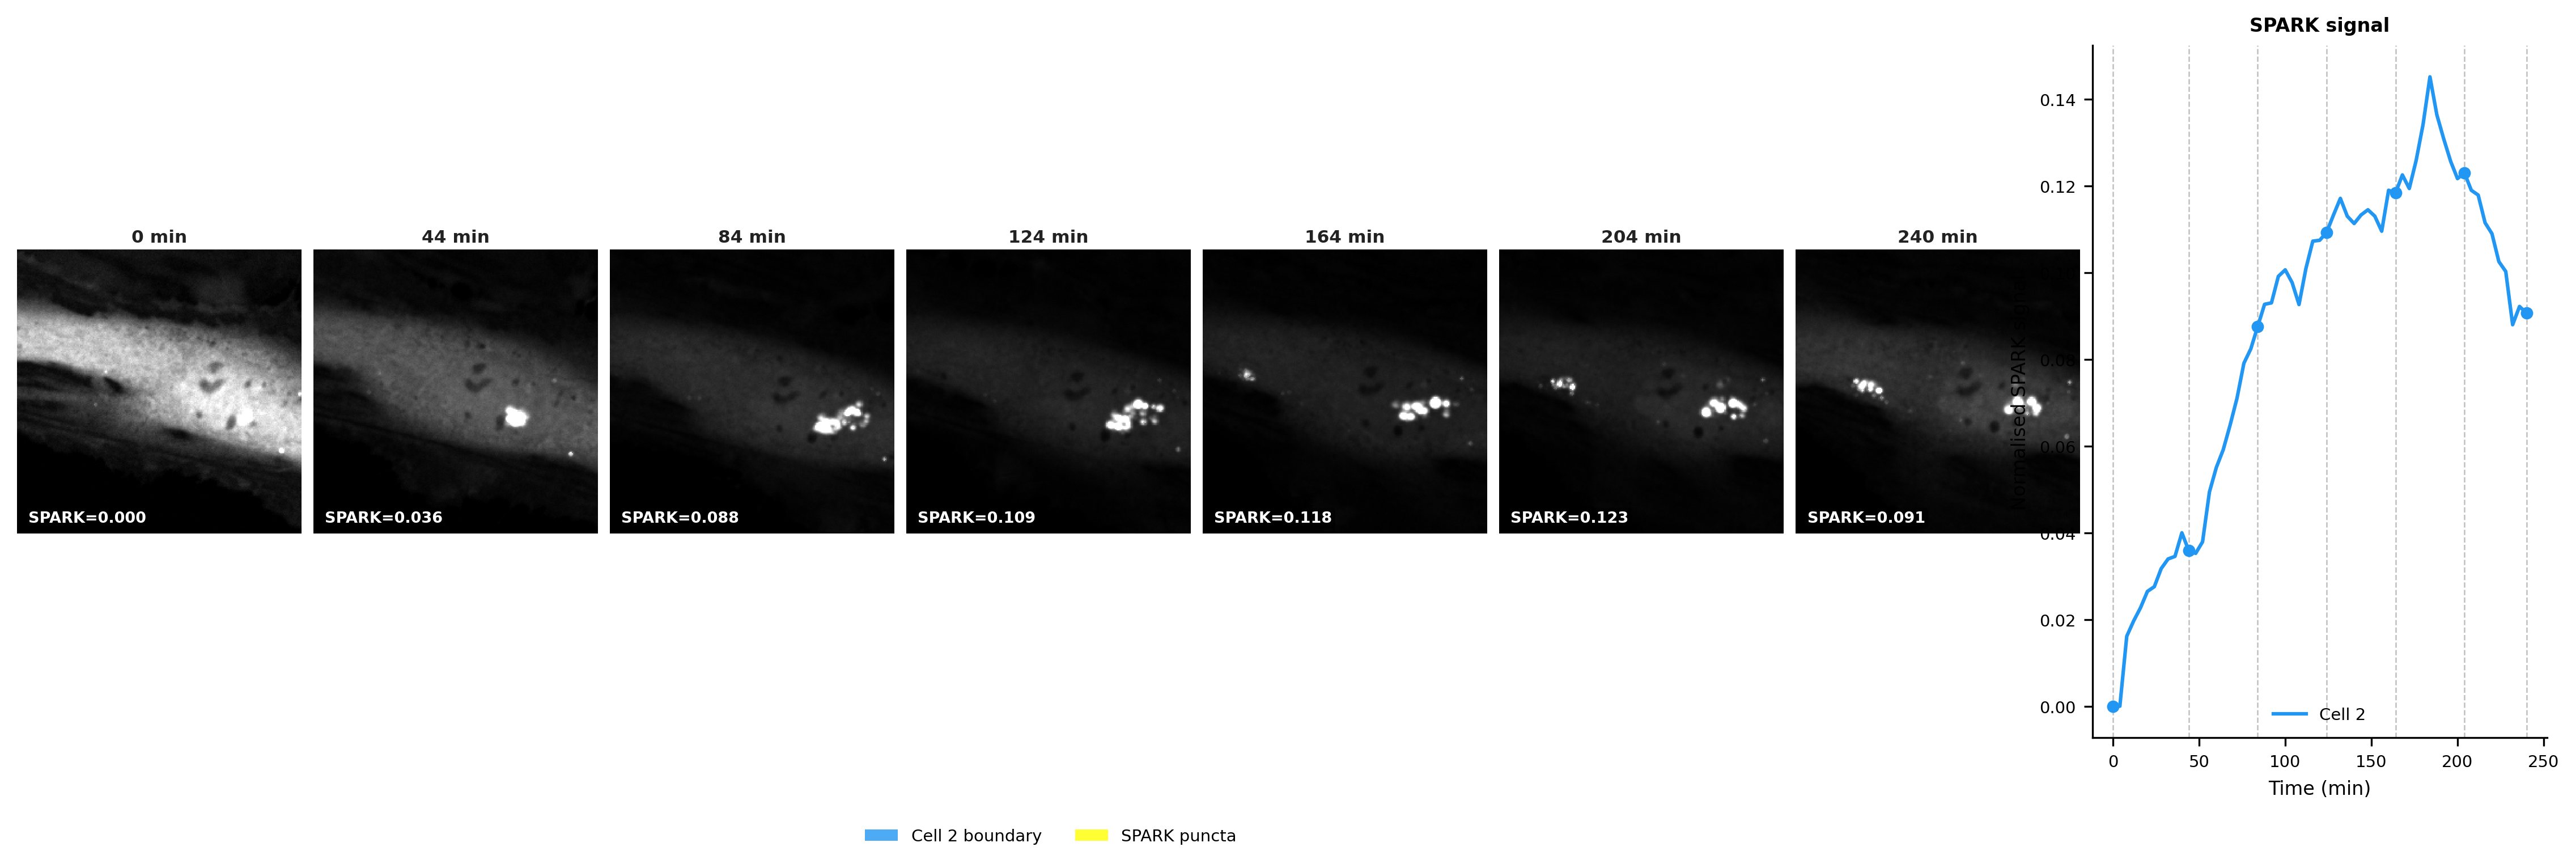

In [120]:
# ── Paper sub-figure: cell 3 & 1 tracked + SPARK signal ─────────────────────
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import tifffile
import numpy as np
from skimage import measure
from skimage.morphology import remove_small_objects
from skimage.segmentation import find_boundaries

# ── parameters ───────────────────────────────────────────────────────────────
FIGURE_FRAMES = [0, 11, 21, 31, 41, 51, 60]
N_FRAMES      = len(FIGURE_FRAMES)
FIGURE_CELLS  = [2]
CELL_COLORS   = {2: '#2196F3', 1: '#F44336'}
HALF_H        = 120    # crop half-height in px — tune to cell size
HALF_W        = 120    # crop half-width  in px

# ── layout ───────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 5.5), dpi=300)
gs  = gridspec.GridSpec(
    len(FIGURE_CELLS), N_FRAMES + 1,
    width_ratios=[1] * N_FRAMES + [1.6],
    wspace=0.04, hspace=0.12,
    left=0.04, right=0.97, top=0.88, bottom=0.14
)

for row, cid in enumerate(FIGURE_CELLS):
    for col, t in enumerate(FIGURE_FRAMES):
        ax = fig.add_subplot(gs[row, col])

        frame_img = tifffile.imread(path, key=t).astype(np.float32)
        cell_mask = (tracked_masks[t] == cid)

        # --- skip if cell not present ---
        if cell_mask.sum() == 0:
            ax.axis('off')
            ax.set_title(f'{FRAME_OFFSET_MIN + t * MINUTES_PER_FRAME:.0f} min'
                         if row == 0 else '', fontsize=7.5, fontweight='bold',
                         pad=3, color='#222222')
            continue

        # --- puncta (mirror quantification loop exactly) ---
        cell_px     = frame_img[cell_mask]
        cell_thresh = np.percentile(cell_px, PUNCTA_CELL_PERCENTILE)
        cell_total  = float(cell_px.sum())

        puncta_mask = (frame_img >= cell_thresh) & cell_mask
        puncta_mask = remove_small_objects(puncta_mask, min_size=MIN_PUNCTA_SIZE)
        p_labeled   = measure.label(puncta_mask)
        for r in measure.regionprops(p_labeled, intensity_image=frame_img):
            if r.area > MAX_PUNCTA_SIZE or r.mean_intensity < MIN_PUNCTA_MEAN_INT:
                puncta_mask[p_labeled == r.label] = False
        p_labeled = measure.label(puncta_mask)
        spark     = float(frame_img[puncta_mask].sum()) / cell_total if cell_total > 0 else 0

        # --- intensity-weighted centroid for drift-robust crop ---
        weights      = frame_img * cell_mask
        total_w      = weights.sum()
        rows_g, cols_g = np.mgrid[0:frame_img.shape[0], 0:frame_img.shape[1]]
        cr = int(np.sum(rows_g * weights) / total_w)
        cc = int(np.sum(cols_g * weights) / total_w)

        r0 = max(cr - HALF_H, 0);  r1 = min(cr + HALF_H, frame_img.shape[0])
        c0 = max(cc - HALF_W, 0);  c1 = min(cc + HALF_W, frame_img.shape[1])

        raw_crop    = frame_img[r0:r1, c0:c1].copy()
        cell_crop   = cell_mask[r0:r1,  c0:c1].copy()
        puncta_crop = puncta_mask[r0:r1, c0:c1].copy()

        # --- contrast stretch within cell (p1–p99.5) ---
        cell_vals = raw_crop[cell_crop]
        lo, hi    = np.percentile(cell_vals, [1, 99.5])
        disp      = np.clip((raw_crop - lo) / (hi - lo + 1e-6), 0, 1)

        # --- render base image ---
        ax.imshow(disp, cmap='gray', interpolation='nearest', aspect='equal')

        # --- cell boundary ---
        boundary   = find_boundaries(cell_crop, mode='outer')
        bd_rgba    = np.zeros((*boundary.shape, 4))
        color_rgb  = plt.matplotlib.colors.to_rgb(CELL_COLORS[cid])
        bd_rgba[boundary, :3] = color_rgb
        bd_rgba[boundary,  3] = 0.9
        # ax.imshow(bd_rgba, interpolation='nearest', aspect='equal')

        # --- puncta overlay (yellow) ---
        if puncta_crop.any():
            p_rgba = np.zeros((*puncta_crop.shape, 4))
            p_rgba[puncta_crop, 0] = 1.0
            p_rgba[puncta_crop, 1] = 1.0
            p_rgba[puncta_crop, 2] = 0.0
            p_rgba[puncta_crop, 3] = 0.85
            # ax.imshow(p_rgba, interpolation='nearest', aspect='equal')

        ax.axis('off')

        # --- column header (top row only) ---
        if row == 0:
            ax.set_title(f'{FRAME_OFFSET_MIN + t * MINUTES_PER_FRAME:.0f} min',
                         fontsize=7.5, fontweight='bold', pad=3, color='#222222')

        # --- SPARK value bottom-left ---
        ax.text(0.04, 0.04, f'SPARK={spark:.3f}',
                transform=ax.transAxes, fontsize=6.5,
                color='white', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', fc='black', alpha=0.45, lw=0))

        # --- row label on first column only ---
        if col == 0:
            ax.set_ylabel(f'Cell {cid}', fontsize=8, fontweight='bold',
                          color=CELL_COLORS[cid], labelpad=4)
            ax.yaxis.set_label_position('left')
            ax.yaxis.label.set_visible(True)

# ── SPARK trace panel ─────────────────────────────────────────────────────────
ax_trace = fig.add_subplot(gs[:, N_FRAMES])

for cid in FIGURE_CELLS:
    sub  = df_spark[df_spark['cell_id'] == cid].sort_values('frame')
    ax_trace.plot(sub['time_min'], sub['spark_norm_ctrl'],
                  color=CELL_COLORS[cid], lw=1.5, label=f'Cell {cid}')
    shown = sub[sub['frame'].isin(FIGURE_FRAMES)]
    ax_trace.scatter(shown['time_min'], shown['spark_norm_ctrl'],
                     color=CELL_COLORS[cid], s=18, zorder=5)

for t in FIGURE_FRAMES:
    ax_trace.axvline(FRAME_OFFSET_MIN + t * MINUTES_PER_FRAME,
                     color='grey', lw=0.6, ls='--', alpha=0.5)

ax_trace.set_xlabel('Time (min)', fontsize=8)
ax_trace.set_ylabel('Normalised SPARK signal', fontsize=8)
ax_trace.set_title('SPARK signal', fontsize=8, fontweight='bold')
ax_trace.tick_params(labelsize=7)
ax_trace.spines[['top', 'right']].set_visible(False)
ax_trace.legend(fontsize=7, frameon=False)

# ── legend ────────────────────────────────────────────────────────────────────
legend_elements = [
    mpatches.Patch(facecolor=CELL_COLORS[cid], alpha=0.8, label=f'Cell {cid} boundary')
    for cid in FIGURE_CELLS
] + [mpatches.Patch(facecolor='yellow', alpha=0.8, label='SPARK puncta')]

fig.legend(handles=legend_elements, loc='lower center', ncol=3,
           fontsize=7, frameon=False, bbox_to_anchor=(0.42, 0.01))

plt.savefig('./spark_examples/spark_paper_figure.pdf', dpi=300, bbox_inches='tight')
plt.savefig('./spark_examples/spark_paper_figure.png', dpi=300, bbox_inches='tight')
print('Saved → spark_paper_figure.pdf / .png')
plt.show()

Global contrast range: lo=145.0  hi=3573.1
Saved → spark_paper_figure.pdf / .png


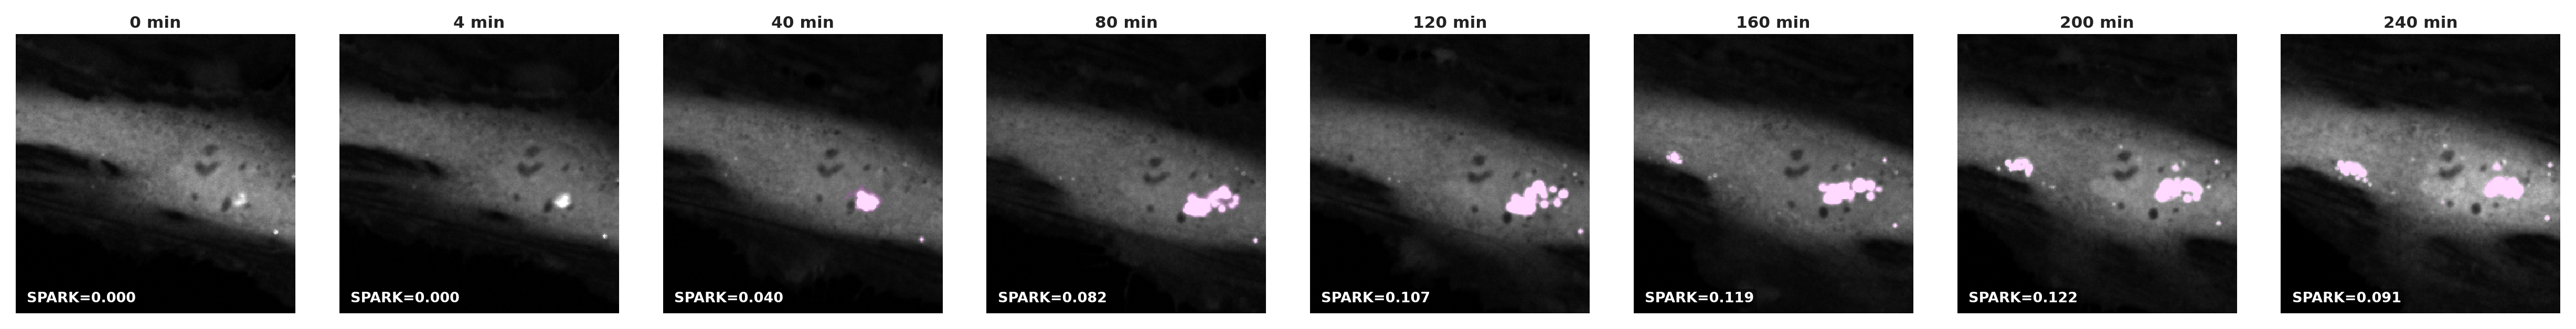

In [137]:
# ── Paper sub-figure: cell tracked + SPARK puncta overlay ────────────────────
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import numpy as np
from skimage import measure
from skimage.morphology import remove_small_objects

# ── parameters ───────────────────────────────────────────────────────────────
FIGURE_FRAMES = [0,1,10, 20, 30, 40, 50, 60]
N_FRAMES      = len(FIGURE_FRAMES)
FIGURE_CELLS  = [2]
CELL_COLORS   = {2: '#2196F3', 1: '#F44336'}
HALF_H        = 120
HALF_W        = 120

# ── compute global contrast normalisation across ALL figure frames ────────────
# collect all in-cell pixel values from every frame that will be shown,
# so contrast stretch is identical across timepoints
all_cell_vals = []
for cid in FIGURE_CELLS:
    for t in FIGURE_FRAMES:
        frame_img = arr[t].astype(np.float32)
        cell_mask = (tracked_masks[t] == cid)
        if cell_mask.sum() == 0:
            continue
        all_cell_vals.append(frame_img[cell_mask])

all_cell_vals = np.concatenate(all_cell_vals)
GLOBAL_LO, GLOBAL_HI = np.percentile(all_cell_vals, [0.5, 99.5])
print(f'Global contrast range: lo={GLOBAL_LO:.1f}  hi={GLOBAL_HI:.1f}')

# ── layout ───────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(N_FRAMES * 2.2, len(FIGURE_CELLS) * 2.4), dpi=300)
gs  = gridspec.GridSpec(
    len(FIGURE_CELLS), N_FRAMES,
    wspace=0.04, hspace=0.12,
    left=0.04, right=0.97, top=0.88, bottom=0.14,
)

for row, cid in enumerate(FIGURE_CELLS):
    for col, t in enumerate(FIGURE_FRAMES):
        ax = fig.add_subplot(gs[row, col])

        frame_img = arr[t].astype(np.float32)
        cell_mask = (tracked_masks[t] == cid)

        # column header (top row only)
        if row == 0:
            ax.set_title(f'{FRAME_OFFSET_MIN + t * MINUTES_PER_FRAME:.0f} min',
                         fontsize=7.5, fontweight='bold', pad=3, color='#222222')

        if cell_mask.sum() == 0:
            ax.axis('off')
            continue

        # ── puncta detection (identical parameters to quantification loop) ────
        cell_px     = frame_img[cell_mask]
        cell_thresh = np.percentile(cell_px, PUNCTA_CELL_PERCENTILE)
        cell_total  = float(cell_px.sum())

        puncta_mask = (frame_img >= cell_thresh) & cell_mask
        puncta_mask = remove_small_objects(puncta_mask, min_size=MIN_PUNCTA_SIZE)
        p_labeled   = measure.label(puncta_mask)
        for r in measure.regionprops(p_labeled, intensity_image=frame_img):
            if r.area > MAX_PUNCTA_SIZE or r.mean_intensity < MIN_PUNCTA_MEAN_INT:
                puncta_mask[p_labeled == r.label] = False
        spark = (float(frame_img[puncta_mask].sum()) / cell_total
                 if cell_total > 0 else 0.0)

        # ── intensity-weighted centroid crop ──────────────────────────────────
        weights        = frame_img * cell_mask
        total_w        = weights.sum()
        rows_g, cols_g = np.mgrid[0:frame_img.shape[0], 0:frame_img.shape[1]]
        cr = int(np.sum(rows_g * weights) / total_w)
        cc = int(np.sum(cols_g * weights) / total_w)
        r0 = max(cr - HALF_H, 0); r1 = min(cr + HALF_H, frame_img.shape[0])
        c0 = max(cc - HALF_W, 0); c1 = min(cc + HALF_W, frame_img.shape[1])

        raw_crop    = frame_img[r0:r1, c0:c1].copy()
        puncta_crop = puncta_mask[r0:r1, c0:c1].copy()

        # ── GLOBAL contrast stretch (same lo/hi for all frames) ───────────────
        disp = np.clip((raw_crop - GLOBAL_LO) / (GLOBAL_HI - GLOBAL_LO + 1e-6),
                       0, 1)

        # ── render ────────────────────────────────────────────────────────────
        ax.imshow(disp, cmap='gray', interpolation='nearest', aspect='equal')

        # puncta overlay: semi-transparent yellow mask
        if puncta_crop.any():
            p_rgba = np.zeros((*puncta_crop.shape, 4))
            p_rgba[puncta_crop, 0] = 1.0   # R
            p_rgba[puncta_crop, 1] = 0.0   # G
            p_rgba[puncta_crop, 2] = 1.0   # B
            p_rgba[puncta_crop, 3] = 0.15  # alpha — semi-transparent
            ax.imshow(p_rgba, interpolation='nearest', aspect='equal')

        ax.axis('off')

        # SPARK value annotation
        ax.text(0.04, 0.04, f'SPARK={spark:.3f}',
                transform=ax.transAxes, fontsize=6.5,
                color='white', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', fc='black', alpha=0.45, lw=0))

        # row label on first column only
        if col == 0:
            ax.set_ylabel(f'Cell {cid}', fontsize=8, fontweight='bold',
                          color=CELL_COLORS[cid], labelpad=4)
            ax.yaxis.set_label_position('left')
            ax.yaxis.label.set_visible(True)


plt.savefig('./spark_examples/spark_paper_figure.pdf', dpi=300, bbox_inches='tight')
plt.savefig('./spark_examples/spark_paper_figure.png', dpi=300, bbox_inches='tight')
print('Saved \u2192 spark_paper_figure.pdf / .png')
plt.show()